# Samuel — regression EDA discovery (pertanyaan belum dikunci)

## tl;dr

Notebook ini merangkum temuan deskriptif aktual dari file lokal yang tersedia. Perbandingan TP1 bersifat opsional; jika input TP1 tidak ada, seluruh analisis TP2 tetap dijalankan. Status dan ringkasan TL;DR di bawah dibentuk dari hasil run.

Analisis ini tetap **DISCOVERY**. Pilihan pertanyaan EDA belum dikunci, dan tidak ada model, prediksi, atau submission yang dibuat.

## Context & Methods

### Asumsi yang perlu dikonfirmasi

- Target dikonfirmasi oleh skema train/test/sample. Header membuktikan nama kolom; makna resmi `threat_rank` masih memerlukan data dictionary.
- Materi kuliah TP1 mendefinisikan `cycle_code` sebagai urutan disclosure, dengan nilai lebih besar lebih baru (PDF lokal, p.16). Penerapan makna itu untuk TP2 masih asumsi yang perlu dicek.
- Tiga periode dibentuk dengan membagi **nilai cycle unik yang terurut**, bukan baris atau target: 47–57, 58–68, 69–79.
- Korelasi Pearson/Spearman dan quantile merangkum baris train yang lengkap. Target test tidak digunakan.
- Target rank diuji terhadap percentile rank rata-rata **dalam setiap cycle** yang dibulatkan 4 desimal. Ini hanya diagnostik pola numerik, bukan bukti algoritme pembentukan target.
- Kelompok target rendah/tinggi memakai batas deskriptif tetap `≤5`/`≥95`; batas ini tidak dipilih dengan hasil prediksi atau validasi.
- Jika TP1 tersedia, perbandingan membandingkan concentration/support, bukan lokasi skala mentah yang tak sebanding. TP1 error metrics dari eksperimen lama bukan performa TP2.

In [1]:
from pathlib import Path
import os,sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file(): raise FileNotFoundError('Run from the TP2 repository.')
sys.path.insert(0,str(ROOT))
from src.data.discovery import run_discovery
tp1_root=Path(os.environ['TP1_DATA_DIR']) if os.environ.get('TP1_DATA_DIR') else ROOT.parent/'TK1'/'tk1-eda-3'/'data'/'raw'
summary=run_discovery(tp1_data_dir=tp1_root)
print('Status:',summary['status'])
print('TP1 comparison:',summary['tp1_target_comparison']['status'])
print('Input hashes:',{k:v['sha256'] for k,v in summary['provenance']['regression_files'].items()})

Status: DISCOVERY_COMPLETE_NOT_A_LOCKED_QUESTION
TP1 comparison: INCLUDED
Input hashes: {'train': '756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082', 'test': '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c', 'sample': '63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533cd39dc854ffc190a32'}


In [2]:
tp2=summary['target_tp2']
tp1=summary['tp1_target_comparison']['tp1']
tp1_line=(f"TP1 impact_load tersedia dengan {tp1['unique']:,} nilai unik; top-1 mengambil {tp1['top_value_shares']['top_1']:.1%} baris TP1."
          if tp1 else "Perbandingan TP1 tidak tersedia; analisis dan grafik TP2 tetap lengkap.")
corr=summary['impact_threat']['overall_correlation']
display(Markdown(f"""### Ringkasan discovery aktual

TP2 memiliki **{tp2['n']:,}** target finite dari {tp2['input_rows']:,} baris input, **{tp2['unique']:,}** nilai unik, rentang `{tp2['min']:.4f}–{tp2['max']:.4f}`, dan **{tp2['integer_like_fraction_abs_tol_1e_8']:.2%}** nilai integer-like (toleransi absolut 1e-8). Korelasi seluruh train: Pearson **{corr['pearson']:.3f}**, Spearman **{corr['spearman']:.3f}**.

{tp1_line}

Hubungan yang teramati bersifat deskriptif: tidak membuktikan sebab-akibat atau error model."""))

### Ringkasan discovery aktual

TP2 memiliki **50,608** target finite dari 50,608 baris input, **34,333** nilai unik, rentang `0.0428–100.0000`, dan **0.29%** nilai integer-like (toleransi absolut 1e-8). Korelasi seluruh train: Pearson **0.637**, Spearman **0.621**.

TP1 impact_load tersedia dengan 80 nilai unik; top-1 mengambil 14.4% baris TP1.

Hubungan yang teramati bersifat deskriptif: tidak membuktikan sebab-akibat atau error model.

## Data

**Train:** 50.608 × 19 · **Test:** 29.421 × 18 · **Sample:** 29.421 × 2. `threat_rank` adalah satu-satunya kolom train-only dan prediksi sample. ID sample berurutan sama dengan test. Target train lengkap, tidak ada ID/row duplikat maupun overlap split. Rincian schema, missingness, dan hash file ada di `reports/audits/regression_audit.json`.

## Results — profil target

Distribusi TP2 dan, bila tersedia, profil TP1 ditampilkan terpisah. Makna/units kedua target berbeda sehingga shape dan concentration dibandingkan, bukan skala mentah.

,n,missing,unique,min,max,mean,sd,top_value_shares
target,,,,,,,,
TP1 impact_load,50608,0,80,22.6469,157.9725,105.271461,30.715042,"{'top_1': 0.14432500790388872, 'top_5': 0.5279..."
TP2 threat_rank,50608,0,34333,0.0428,100.0000,50.032604,28.867433,"{'top_1': 0.0014424596901675625, 'top_5': 0.00..."


TP2 target decile occupancy:


,band,n,share
0,"(-0.001, 10.0]",5058,0.099945
1,"(10.0, 20.0]",5042,0.099629
2,"(20.0, 30.0]",5072,0.100221
3,"(30.0, 40.0]",5050,0.099787
4,"(40.0, 50.0]",5076,0.100300
5,"(50.0, 60.0]",5048,0.099747
6,"(60.0, 70.0]",5054,0.099866
7,"(70.0, 80.0]",5069,0.100162
8,"(80.0, 90.0]",5072,0.100221
9,"(90.0, 100.0]",5067,0.100123


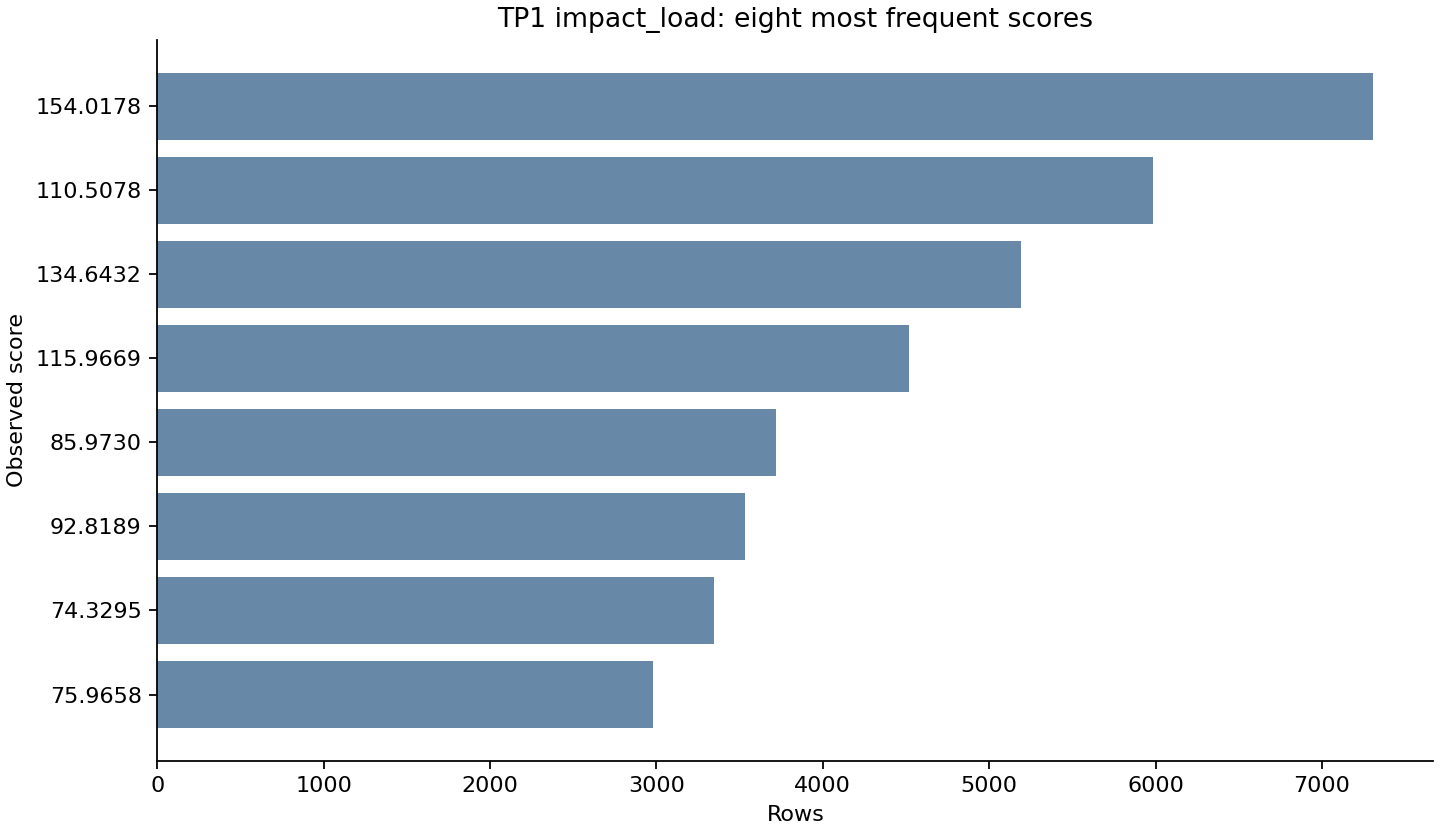

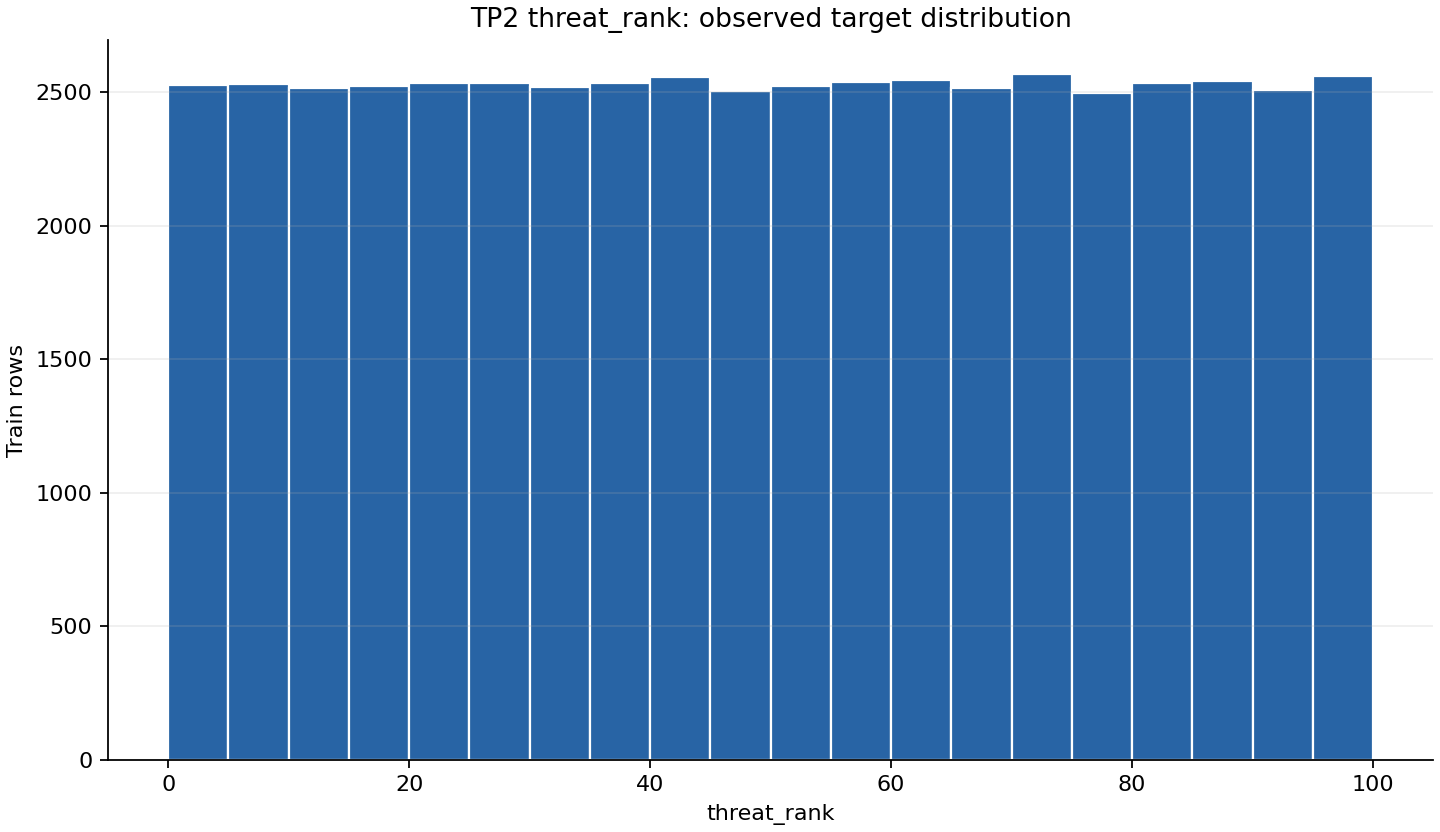

In [3]:
profiles=summary['tp1_target_comparison']
rows=[{'target':'TP2 threat_rank',**{k:profiles['tp2'][k] for k in ('n','missing','unique','min','max','mean','sd','top_value_shares')}}]
if profiles['tp1']:
    rows.insert(0,{'target':'TP1 impact_load',**{k:profiles['tp1'][k] for k in ('n','missing','unique','min','max','mean','sd','top_value_shares')}})
else:
    print('TP1 profile omitted:',profiles['status'])
display(pd.DataFrame(rows).set_index('target'))
print('TP2 target decile occupancy:')
display(pd.DataFrame(summary['impact_threat']['target_decile_bins']))
figures=set(summary['figures'])
if 'discovery_tp1_top_scores.png' in figures:
    display(Image(filename=str(ROOT/'reports'/'eda'/'discovery_tp1_top_scores.png'),alt='TP1 impact_load most frequent values'))
else:
    print('TP1-only figure skipped: optional TP1 comparison unavailable.')
if 'discovery_tp2_target_histogram.png' in figures:
    display(Image(filename=str(ROOT/'reports'/'eda'/'discovery_tp2_target_histogram.png'),alt='TP2 threat_rank histogram'))

## Results — target rank vs impact/cycle

Korelasi per cycle bervariasi; garis tiap cycle tidak mewakili confidence interval. Median dan quantiles menggambarkan sebaran aktual, bukan uncertainty of the mean. Target marginal yang tetap bisa menutupi perubahan hubungan kondisional.

,period,cycles,n,Pearson,Spearman,target median,target p10,target p90
0,period_01,47–57,13546,0.4994,0.4773,50.0323,9.9813,90.0263
1,period_02,58–68,16736,0.6722,0.6631,50.0128,10.0333,89.9978
2,period_03,69–79,20326,0.6964,0.6798,50.0384,10.0385,90.0166


,cycle_code,n,pearson,spearman,threat_median,threat_p10,threat_p90
0,47,1342,0.4487,0.4148,50.0559,10.0670,90.0074
1,48,977,0.5123,0.4844,52.0983,10.0921,90.0102
2,49,1255,0.4541,0.4284,50.0000,9.7610,90.0080
3,50,1111,0.4904,0.4737,50.0450,10.0810,90.0090
4,51,1535,0.5482,0.5343,50.0326,10.0717,90.0065
5,52,1565,0.4756,0.4534,50.0319,10.0958,90.0064
6,53,1371,0.4805,0.4406,50.0365,10.0656,90.0073
7,54,1256,0.5147,0.4940,50.0398,9.9522,89.9482


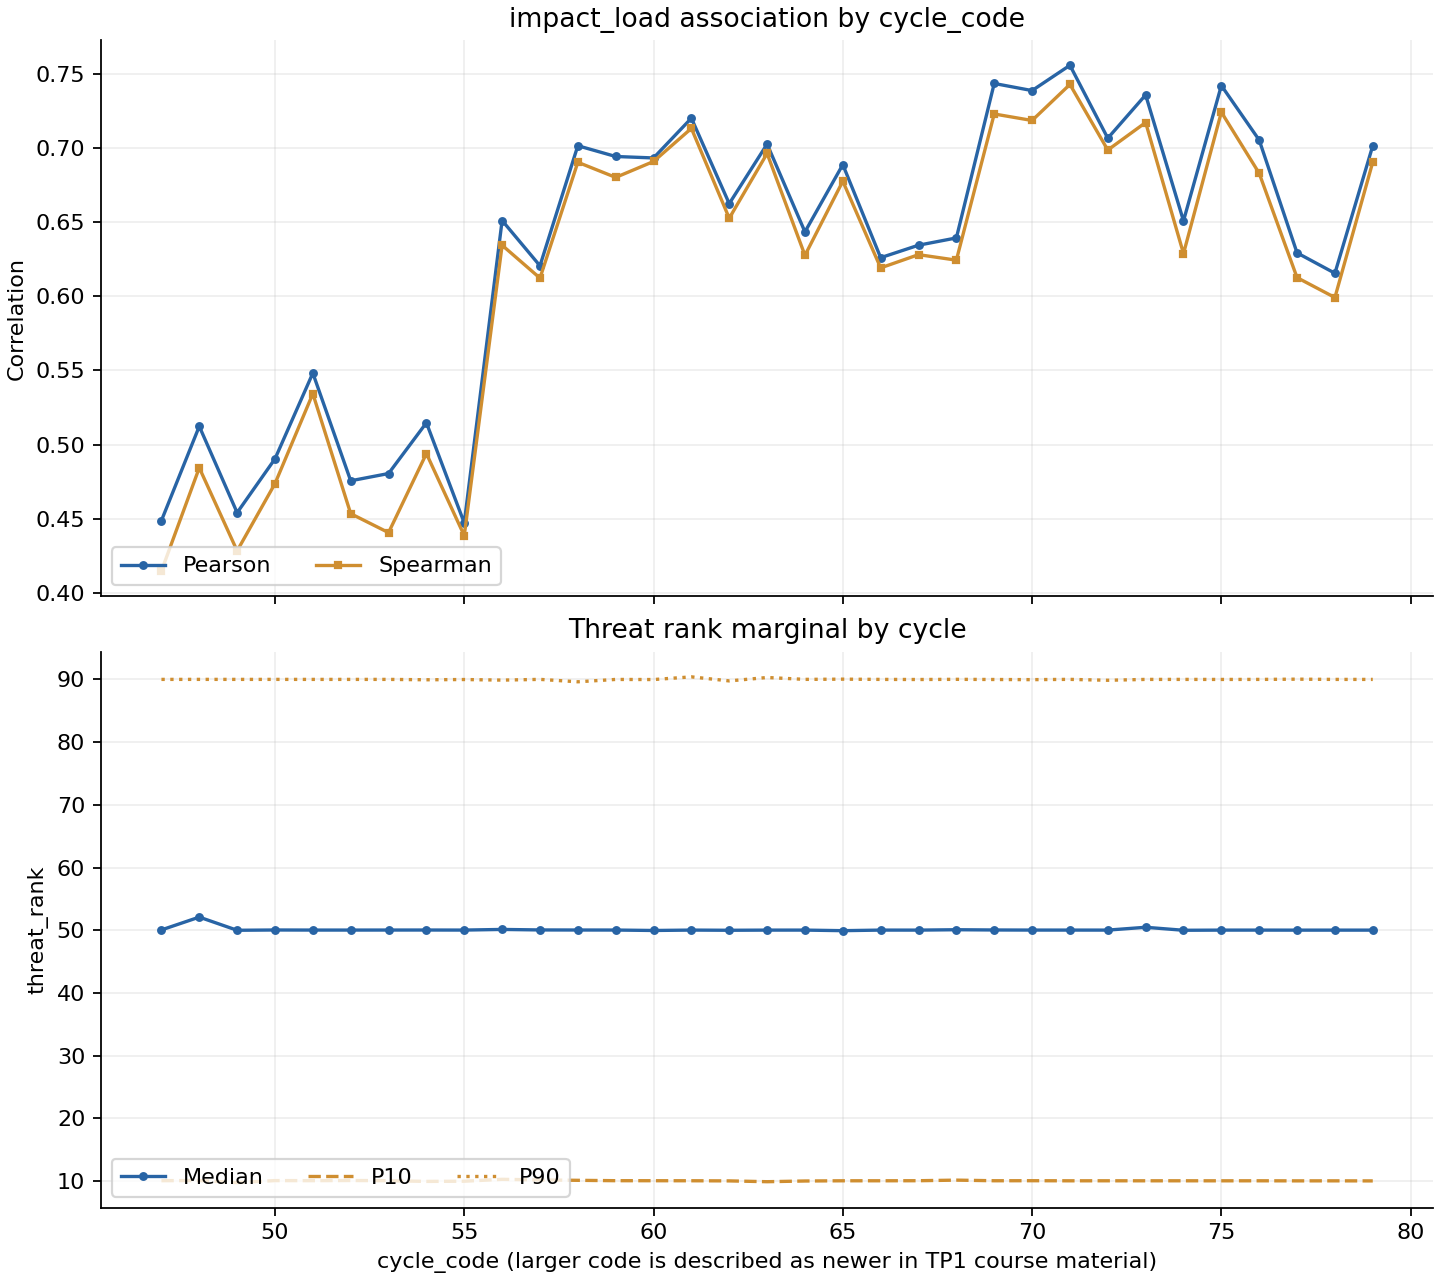

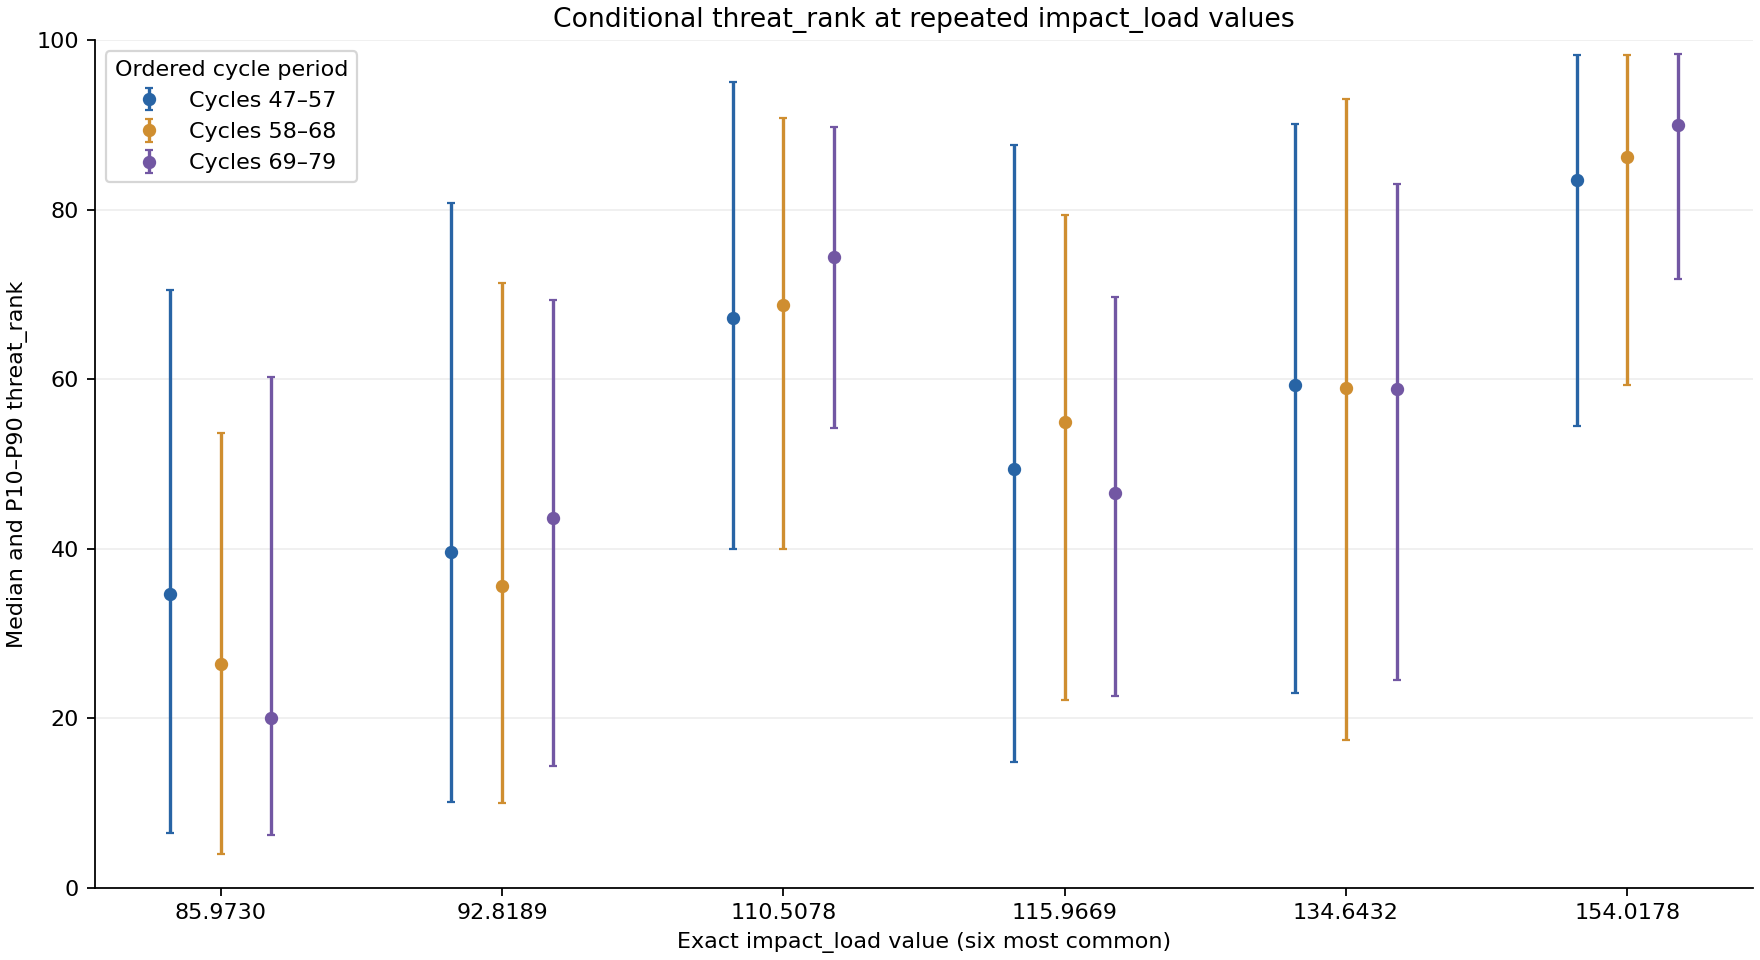

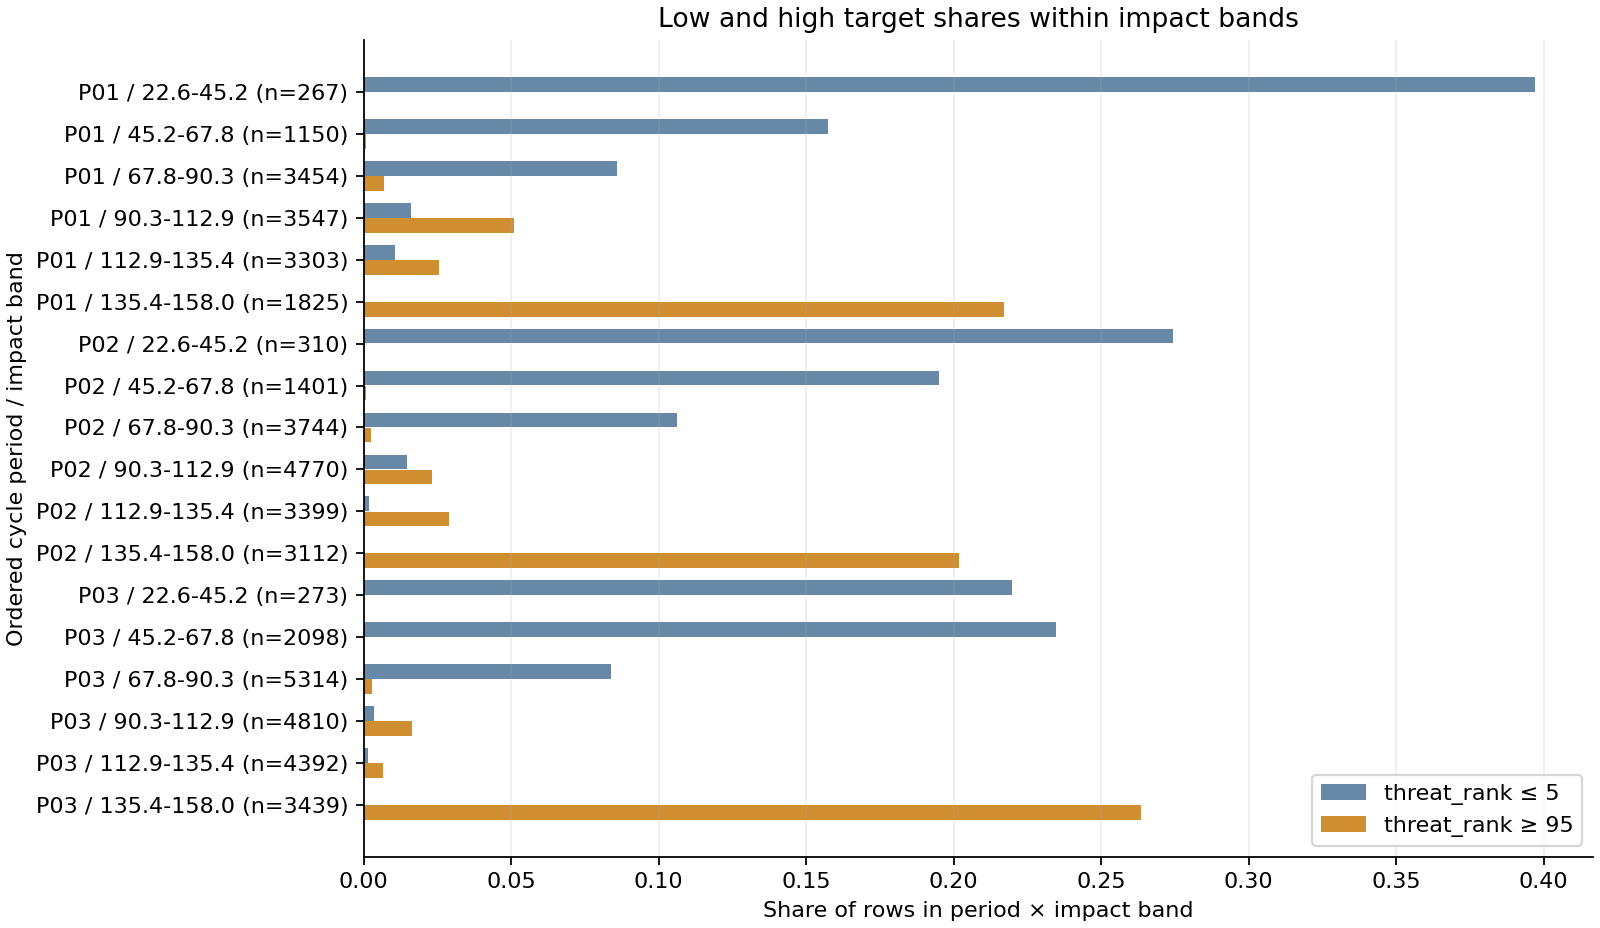

In [4]:
display(pd.DataFrame([{'period':p['period'],'cycles':f"{p['cycle_min']}–{p['cycle_max']}",'n':p['n'],
                     'Pearson':p['impact_threat_correlation']['pearson'],'Spearman':p['impact_threat_correlation']['spearman'],
                     'target median':p['target']['quantiles']['50'],'target p10':p['target']['quantiles']['10'],
                     'target p90':p['target']['quantiles']['90']} for p in summary['impact_threat']['by_cycle_period']]).round(4))
per_cycle=pd.DataFrame(summary['impact_threat']['by_cycle'])
display(per_cycle[['cycle_code','n','pearson','spearman','threat_median','threat_p10','threat_p90']].round(4).head(8))
for name,alt in [('discovery_cycle_relationship.png','Per-cycle correlations and target marginal quantiles'),
                 ('discovery_conditional_spread.png','Conditional threat spread by repeated impact and period'),
                 ('discovery_tail_by_impact_cycle.png','Low and high target shares by cycle period and impact band')]:
    if name in figures: display(Image(filename=str(ROOT/'reports'/'eda'/name),alt=alt))

### Variasi pada impact_load yang sama

`impact_load` berulang persis pada sebagian besar record. Banyak tingkat impact yang sama mengandung rentang target lebar; tabel dan grafik berikut membandingkan enam nilai impact terpadat per periode dengan skala target bersama.

In [5]:
rep=pd.DataFrame(summary['repeated_impact_values_by_period'])
top=rep[rep.period=='all'].nlargest(12,'n').impact_load
display(rep[rep.impact_load.isin(top)].sort_values(['impact_load','period'])
        [['impact_load','period','n','median','p10','p90','iqr']].round(4).head(36))
display(pd.DataFrame(summary['candidate_signal_examples']))

,impact_load,period,n,median,p10,p90,iqr
32,56.9670,all,1772,14.7816,2.6311,53.3026,24.7017
33,56.9670,period_01,455,21.5171,2.3739,68.9853,33.2424
34,56.9670,period_02,554,11.7012,2.0463,42.9428,15.6679
35,56.9670,period_03,763,15.1874,3.7372,51.0897,22.3911
44,64.7106,all,1482,14.4813,0.9879,48.5555,28.2755
45,64.7106,period_01,262,27.6718,5.2160,57.5106,27.7086
46,64.7106,period_02,453,16.0014,1.7419,38.9029,17.7693
47,64.7106,period_03,767,6.9023,0.9636,47.7839,28.2522
36,72.7026,all,1683,52.1435,22.7646,79.9658,30.2737
37,72.7026,period_01,496,53.0660,20.7107,89.0830,33.4287


,comparison,values
0,fixed recurring impact levels,"[{'impact_load': 110.5078, 'n': 5984, 'median'..."
1,fixed recurring impact levels,"[{'impact_load': 134.6432, 'n': 5192, 'median'..."


### Pola rank per cycle dan ekor target

An exact within-cycle percentile match occurs for the full training target under the tested formula. This may reflect how the score is encoded; it does not prove target lineage. The target test labels are absent, so no target comparison or error analysis on test exists.

In [6]:
display(summary['within_cycle_percentile_diagnostic'])
tails=pd.DataFrame(summary['conditional_extremes']['by_period_impact_band'])
display(tails[['period','impact_band','n','low_n_le_5','low_share','high_n_ge_95','high_share']].round(4))

{'diagnostic': 'Compare observed threat_rank with a within-cycle and pooled empirical average-rank percentile rounded to four decimals.',
 'within_cycle': {'exact_match_rows': 50608,
  'rows': 50608,
  'exact_match_fraction': 1.0,
  'max_absolute_difference': 0.0,
  'mean_absolute_difference': 0.0,
  'continuous_percentile_unrounded_rows': 634,
  'continuous_percentile_unrounded_max_absolute_difference': 4.9974450689660443e-05},
 'pooled': {'exact_match_rows': 25,
  'rows': 50608,
  'exact_match_fraction': 0.0004939930445779324,
  'max_absolute_difference': 0.14639999999999997,
  'mean_absolute_difference': 0.03493682224154284},
 'interpretation_limit': 'An exact numerical match is a distributional construction clue only. It does not prove the target-generation algorithm, causal meaning, or permission to reconstruct or use labels outside the official task.'}

,period,impact_band,n,low_n_le_5,low_share,high_n_ge_95,high_share
0,period_01,"(22.645999999999997, 45.201]",267,106,0.3970,0,0.0000
1,period_01,"(45.201, 67.755]",1150,181,0.1574,1,0.0009
2,period_01,"(67.755, 90.31]",3454,296,0.0857,24,0.0069
3,period_01,"(90.31, 112.864]",3547,57,0.0161,180,0.0507
4,period_01,"(112.864, 135.418]",3303,35,0.0106,84,0.0254
5,period_01,"(135.418, 157.972]",1825,0,0.0000,396,0.2170
6,period_02,"(22.645999999999997, 45.201]",310,85,0.2742,0,0.0000
7,period_02,"(45.201, 67.755]",1401,273,0.1949,1,0.0007
8,period_02,"(67.755, 90.31]",3744,398,0.1063,9,0.0024
9,period_02,"(90.31, 112.864]",4770,70,0.0147,111,0.0233


## Kandidat pertanyaan EDA

Pengukuran dan visualisasi di notebook ini menjadi bukti pendukung, sementara tiga sampai lima kandidat pertanyaan beserta bukti dan rekomendasi terbaik dicatat pada [laporan rekomendasi discovery](../../reports/eda/REGRESSION_DISCOVERY.md). Notebook ini berstatus **DISCOVERY** dan tidak mengunci pertanyaan secara mandiri.

## Takeaways

TP2 `threat_rank` memiliki support yang padat, hubungan positif dengan `impact_load`, variasi kekuatan asosiasi antarcycle, dan sebaran target yang lebar pada nilai impact yang sama. Rank sangat sesuai dengan percentile cycle masing-masing, tetapi ini hanya petunjuk konstruksi numerik, bukan pembuktian lineage. Jika dibandingkan, temuan over/underprediction ekstrem TP1 hanya menjadi motivasi untuk menelaah support dan sebaran kondisional TP2; itu bukan bukti bahwa error TP1 berulang.